# SARIMAX — Previsão do Preço Diário do Arroz com a Precipitação

**TCC — Sistemas de Informação | PUCRS**
Bruno Origem Noronha

Este notebook implementa o **SARIMAX** em **granularidade diária**: um modelo SARIMA acrescido de uma **variável exógena** (explicativa).
O "X" do nome vem de *eXogenous*.

- **Variável alvo (y, endógena):** preço diário do arroz em reais (`preco_brl`)
- **Variável exógena (X):** precipitação diária (`precipitacao_mm`), média das praças produtoras de arroz do RS (Rio Grande, Santa Vitória do Palmar e Uruguaiana)

O objetivo é responder: **a chuva nas regiões produtoras ajuda a explicar a flutuação diária do preço do arroz?**

Por que **dados diários**? O mercado de arroz reage dia a dia a notícias de safra, clima e câmbio.
A média mensal suaviza essas oscilações; a série diária preserva a dinâmica de curto prazo que queremos prever.

Roteiro:
1. Carregamento, alinhamento diário e divisão cronológica (treino até 31/12/2025 · teste nos primeiros 30 dias de 2026)
2. Análise de estacionariedade (teste ADF)
3. Ajuste do modelo SARIMAX diário
4. Previsão no período de teste e métricas (RMSE, MAE, MAPE)
5. Visualização gráfica e exportação

In [1]:
# Bibliotecas
import os
import warnings
warnings.filterwarnings("ignore")   # esconde avisos internos das bibliotecas, para a saída ficar limpa

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from statsmodels.tsa.stattools import adfuller           # teste de estacionariedade
from statsmodels.tsa.statespace.sarimax import SARIMAX   # modelo SARIMAX

# Pasta onde salvamos o gráfico e as métricas
PASTA_SAIDA = "outputs"
os.makedirs(PASTA_SAIDA, exist_ok=True)

## 1. Carregamento e alinhamento diário

### 1.1 Leitura e unificação das bases

- **Preço (y):** o arquivo `preco_arroz_limpo.csv` já está em frequência diária, um registro por dia de calendário.
- **Precipitação (X):** o arquivo `dados_climaticos_arroz_limpos.csv` traz **uma linha por praça e por dia**.
  Para obter um único valor por data, calculamos a **média da precipitação entre as praças** (`groupby("data").mean()`).
  A média funciona como um indicador regional de chuva sobre a zona arrozeira.
- **Alinhamento:** unimos as duas tabelas pela **data**, mantendo o calendário do preço (`how="left"`), e fixamos a
  frequência diária (`asfreq("D")`). Assim, cada dia tem exatamente um preço e um valor de chuva.
- **Valores ausentes:** se algum dia não tiver registro de chuva, preenchemos com **0 mm** (ausência de chuva registrada).
  No preço, eventuais lacunas são preenchidas com o **último valor conhecido** (`ffill`), prática padrão em séries de mercado.

In [2]:
# Lê os dois CSVs
arroz = pd.read_csv("../data/processed/preco_arroz_limpo.csv",           parse_dates=["data"], index_col="data")
clima = pd.read_csv("../data/processed/dados_climaticos_arroz_limpos.csv", parse_dates=["data"])

# Precipitação: uma linha por praça e dia -> média das praças por data
chuva = clima.groupby("data")["precipitacao_mm"].mean()

# Une as bases pela data e garante frequência diária contínua
dados = arroz[["preco_brl"]].join(chuva, how="left").asfreq("D")

print("Valores ausentes antes do tratamento:")
print(dados.isna().sum().to_string())

# Tratamento de ausentes
dados["preco_brl"]       = dados["preco_brl"].ffill()
dados["precipitacao_mm"] = dados["precipitacao_mm"].fillna(0)

print(f"\nPraças utilizadas: {', '.join(sorted(clima['praca'].unique()))}")
print(f"Período total: {dados.index[0]:%d/%m/%Y} a {dados.index[-1]:%d/%m/%Y} ({len(dados)} dias)")
dados.head()

Valores ausentes antes do tratamento:
preco_brl          0
precipitacao_mm    0

Praças utilizadas: RioGrande, SantaVitoria, Uruguaiana
Período total: 02/01/2008 a 20/04/2026 (6684 dias)


,preco_brl,precipitacao_mm
data,,
2008-01-02,23.79,1.400000
2008-01-03,24.14,27.200000
2008-01-04,24.23,8.200000
2008-01-05,24.23,0.133333
2008-01-06,24.23,0.066667


### 1.2 Divisão cronológica: treino vs. teste

Em séries temporais a divisão **nunca é aleatória**: o modelo só pode aprender com o passado e ser avaliado no futuro.

| Conjunto | Período | Justificativa |
|---|---|---|
| **Treino** | início da série até **31/12/2025** | o modelo absorve todo o histórico, incluindo choques profundos como a **pandemia de 2020** e as **enchentes no Rio Grande do Sul em 2024** |
| **Teste** | **01/01/2026 a 30/01/2026** (30 dias) | horizonte de **curto prazo**, coerente com o uso prático de uma previsão diária |

A constante `HORIZONTE` define o tamanho do teste e pode ser ajustada entre 15 e 30 dias.

In [3]:
FIM_TREINO = "2025-12-31"
HORIZONTE  = 30   # dias de teste no início de 2026 (entre 15 e 30)

treino = dados.loc[:FIM_TREINO]
teste  = dados.loc["2026-01-01":].iloc[:HORIZONTE]

y_treino, y_teste = treino["preco_brl"], teste["preco_brl"]
X_treino, X_teste = treino[["precipitacao_mm"]], teste[["precipitacao_mm"]]   # tabela, como o SARIMAX espera

print(f"Treino: {len(y_treino)} dias ({y_treino.index[0]:%d/%m/%Y} a {y_treino.index[-1]:%d/%m/%Y})")
print(f"Teste : {len(y_teste)} dias ({y_teste.index[0]:%d/%m/%Y} a {y_teste.index[-1]:%d/%m/%Y})")

Treino: 6574 dias (02/01/2008 a 31/12/2025)
Teste : 30 dias (01/01/2026 a 30/01/2026)


### 1.3 Visão geral da série de treino

O gráfico mostra o preço diário (eixo esquerdo) e a precipitação média (eixo direito).
Os destaques marcam os dois choques que o treino precisa conter: a **pandemia (2020)** e as **enchentes no RS (abr–jun/2024)**.

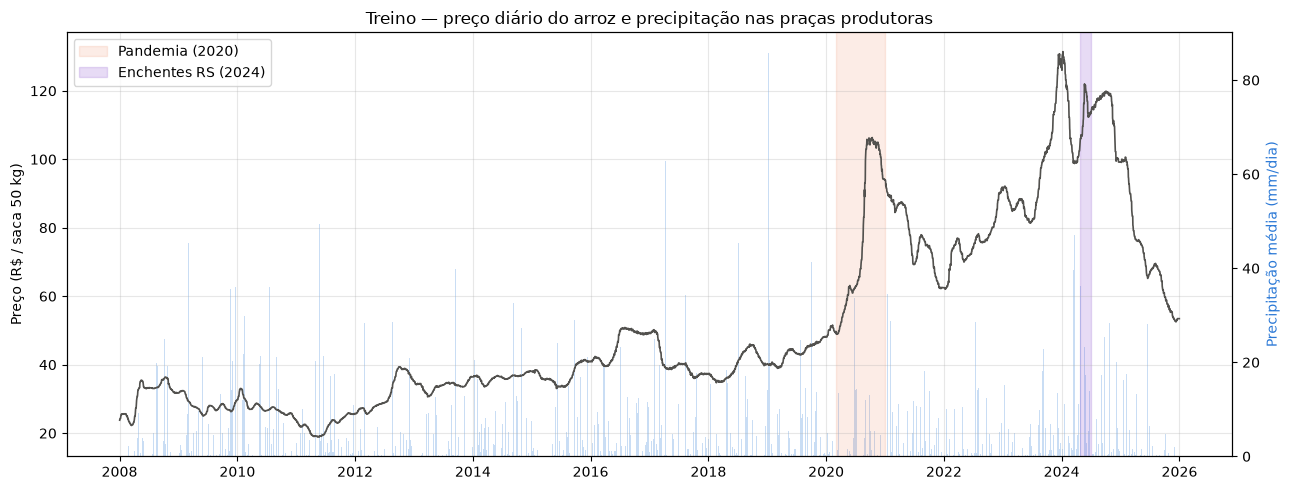

In [4]:
fig, ax1 = plt.subplots(figsize=(13, 5))

ax2 = ax1.twinx()   # segundo eixo vertical para a chuva
ax2.bar(X_treino.index, X_treino["precipitacao_mm"], width=1, color="#2a78d6", alpha=0.25)
ax2.set_ylabel("Precipitação média (mm/dia)", color="#2a78d6")

ax1.plot(y_treino, color="#52514e", lw=1.2)
ax1.set_ylabel("Preço (R$ / saca 50 kg)")
ax1.set_zorder(ax2.get_zorder() + 1)   # linha do preço por cima das barras
ax1.patch.set_visible(False)

ax1.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-12-31"), color="#eb6834", alpha=0.12, label="Pandemia (2020)")
ax1.axvspan(pd.Timestamp("2024-04-27"), pd.Timestamp("2024-06-30"), color="#7a3cc8", alpha=0.18, label="Enchentes RS (2024)")

ax1.set_title("Treino — preço diário do arroz e precipitação nas praças produtoras")
ax1.grid(alpha=0.3)
ax1.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 2. Análise de estacionariedade (teste ADF)

Os modelos ARIMA/SARIMA exigem uma série **estacionária**: média e variância estáveis ao longo do tempo.
O teste **ADF (Augmented Dickey-Fuller)** verifica isso:

- **Hipótese nula (H₀):** a série tem raiz unitária, ou seja, **não é estacionária**.
- **Regra de decisão:** p-valor **< 0,05** → rejeitamos H₀ → a série é estacionária.

Testamos o preço e a precipitação no nível original e na **primeira diferença** (variação de um dia para o outro).
Se o preço só ficar estacionário após diferenciar, usamos **d = 1**.

In [5]:
def teste_adf(s, nome):
    estatistica, p_valor = adfuller(s)[:2]   # 1º item: estatística; 2º item: p-valor
    conclusao = "estacionária" if p_valor < 0.05 else "NÃO estacionária"
    print(f"{nome:<30} ADF = {estatistica:8.3f}   p-valor = {p_valor:.4f}  ->  {conclusao}")

teste_adf(y_treino,                                  "Arroz — original")
teste_adf(y_treino.diff().dropna(),                  "Arroz — 1ª diferença")
teste_adf(X_treino["precipitacao_mm"],               "Precipitação — original")

Arroz — original               ADF =   -1.835   p-valor = 0.3634  ->  NÃO estacionária
Arroz — 1ª diferença           ADF =   -9.705   p-valor = 0.0000  ->  estacionária
Precipitação — original        ADF =  -14.405   p-valor = 0.0000  ->  estacionária


**Leitura:**

- O **preço original não é estacionário** (p-valor acima de 0,05): ele tem tendência de longo prazo e mudanças de patamar.
- A **primeira diferença é estacionária**, portanto adotamos **d = 1**: o modelo trabalha com as **variações diárias** do preço.
- A **precipitação já é estacionária** no nível: a chuva oscila em torno de um padrão climático estável, sem tendência.

O SARIMAX aplica a diferenciação ao modelo inteiro, então o efeito da chuva é estimado sobre a **variação diária do preço**.
Isso evita a **regressão espúria**, em que duas séries com tendência parecem relacionadas sem que exista relação real.

### 2.1 Por que sazonalidade semanal (s = 7)?

Com dados diários, a escolha do período sazonal `s` precisa refletir um ciclo real e computacionalmente viável:

- **s = 365 (anual)** tornaria o modelo inviável: o espaço de estados teria centenas de dimensões e o ajuste levaria horas, com alto risco de não convergir.
- **s = 7 (semanal)** captura um padrão concreto da série: **não há pregão aos sábados e domingos**, então o preço é repetido nesses dias
  e a variação diária é sempre zero. A tabela abaixo comprova isso.

In [6]:
variacao = y_treino.diff().dropna()
dias = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado", "Domingo"]

pd.DataFrame({
    "% de dias sem variação": (variacao == 0).groupby(variacao.index.dayofweek).mean().mul(100).round(1).values,
    "Variação absoluta média (R$)": variacao.abs().groupby(variacao.index.dayofweek).mean().round(3).values,
}, index=dias)

,% de dias sem variação,Variação absoluta média (R$)
Segunda,11.6,0.106
Terça,6.1,0.336
Quarta,6.2,0.186
Quinta,7.1,0.188
Sexta,9.7,0.147
Sábado,100.0,0.000
Domingo,100.0,0.000


Sábados e domingos têm **100% dos dias sem variação**: é um ciclo semanal determinístico que o componente sazonal com `s = 7` aprende a reproduzir.

## 3. Ajuste do modelo SARIMAX diário

O modelo é **SARIMAX(p, d, q)(P, D, Q, s)** com a precipitação como variável exógena:

| Parâmetro | Valor | Significado |
|---|---|---|
| **p** | 1 | usa a variação do **dia anterior** (parte autorregressiva) |
| **d** | 1 | **1 diferenciação** para tornar a série estacionária (resultado do ADF) |
| **q** | 1 | corrige pelo **erro de previsão do dia anterior** (média móvel) |
| **P** | 1 | usa a variação do **mesmo dia da semana anterior** (autorregressivo sazonal) |
| **D** | 0 | sem diferenciação sazonal: a variação diária já é estacionária |
| **Q** | 1 | corrige pelo erro do **mesmo dia da semana anterior** (média móvel sazonal) |
| **s** | 7 | ciclo sazonal **semanal** (dados diários, sem pregão no fim de semana) |
| **exog** | precipitação | chuva média diária nas praças produtoras, como **variável explicativa** |

A ordem é **parcimoniosa** (poucos parâmetros): com mais de 6.500 observações diárias, ordens maiores aumentam o custo
computacional sem ganho relevante de ajuste (critério AIC). Em testes preliminares, incluir o componente semanal reduziu o AIC
de cerca de 2.770 para cerca de 2.100 em relação a um ARIMA(1,1,1) sem sazonalidade.

Na prática, o modelo é uma **regressão do preço do arroz sobre a chuva**, em que o erro dessa regressão segue um SARIMA.
O resultado traz um **coeficiente para a precipitação** (linha `precipitacao_mm` do resumo):

- **sinal**: positivo indica que mais chuva acompanha alta no preço; negativo, queda;
- **P>|z|** (p-valor): abaixo de 0,05 indica efeito estatisticamente significativo.

O modelo é ajustado **apenas com o treino**. Usamos `maxiter=200` para garantir a convergência do otimizador.

In [7]:
ORDEM         = (1, 1, 1)      # (p, d, q)
ORDEM_SAZONAL = (1, 0, 1, 7)   # (P, D, Q, s)

modelo = SARIMAX(endog=y_treino, exog=X_treino, order=ORDEM, seasonal_order=ORDEM_SAZONAL)
resultado = modelo.fit(disp=False, maxiter=200)   # disp=False esconde as mensagens da otimização

print(resultado.summary())
print(f"\nOtimização convergiu: {resultado.mle_retvals['converged']}")

# Destaque do efeito da chuva
coef   = resultado.params["precipitacao_mm"]
p_coef = resultado.pvalues["precipitacao_mm"]
print(f"Coeficiente da precipitação = {coef:.5f}  (p-valor = {p_coef:.4f})")
if p_coef < 0.05:
    print(f"Significativo: cada 1 mm de chuva a mais muda o preço diário em R$ {coef:.5f}, em média.")
else:
    print("NÃO significativo (p-valor >= 0,05): não há evidência de que a chuva do mesmo dia explique a variação diária do preço.")

                                     SARIMAX Results                                     
Dep. Variable:                         preco_brl   No. Observations:                 6574
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 7)   Log Likelihood               -1045.692
Date:                           Tue, 27 Oct 2026   AIC                           2103.384
Time:                                   14:26:03   BIC                           2144.129
Sample:                               01-02-2008   HQIC                          2117.469
                                    - 12-31-2025                                         
Covariance Type:                             opg                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
precipitacao_mm    -0.0002      0.000     -0.451      0.652      -0.001       0.001
ar.L1               0.9454  

## 4. Previsão no período de teste e métricas

O modelo prevê os **30 dias de janeiro de 2026 de uma só vez**, sem ter visto o preço do arroz nesse período (*out-of-sample*).
Para isso, o SARIMAX **precisa do valor da precipitação em cada dia futuro**, por isso passamos `exog=X_teste`.

> **Atenção (limitação):** usamos a chuva **real** observada no período de teste. Isso mede o quanto a precipitação
> *explica* o preço. Numa previsão operacional, a chuva futura viria de uma previsão meteorológica, o que acrescentaria erro.

As métricas são calculadas **manualmente com `numpy`**, a partir das fórmulas, sendo $y_t$ o preço real, $\hat{y}_t$ o previsto e $n$ o número de dias:

| Métrica | Fórmula | O que mede |
|---|---|---|
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y_t - \hat{y}_t)^2}$ | erro em R\$; pune mais os erros grandes |
| **MAE** | $\frac{1}{n}\sum \lvert y_t - \hat{y}_t \rvert$ | "em média, erramos X reais por dia" |
| **MAPE** | $\frac{100}{n}\sum \left\lvert \frac{y_t - \hat{y}_t}{y_t} \right\rvert$ | "em média, erramos X% do preço" |

In [8]:
# Previsão para os dias do teste, informando a chuva desses dias
previsao  = resultado.get_forecast(steps=len(y_teste), exog=X_teste)
y_prev    = previsao.predicted_mean
intervalo = previsao.conf_int(alpha=0.05)   # limites inferior e superior (95%)

# Métricas calculadas diretamente pelas fórmulas
erro = y_teste.values - y_prev.values
rmse = np.sqrt(np.mean(erro ** 2))
mae  = np.mean(np.abs(erro))
mape = np.mean(np.abs(erro / y_teste.values)) * 100

print(f"RMSE = R$ {rmse:.2f}")
print(f"MAE  = R$ {mae:.2f}")
print(f"MAPE = {mape:.2f}%")

RMSE = R$ 0.37
MAE  = R$ 0.30
MAPE = 0.56%


Tabela dia a dia do período de teste, para inspecionar onde o modelo acerta e erra:

In [9]:
comparacao = pd.DataFrame({
    "Real (R$)":     y_teste,
    "Previsto (R$)": y_prev,
    "Erro (R$)":     y_teste - y_prev,
    "Chuva (mm)":    X_teste["precipitacao_mm"],
}).round(2)
comparacao.index = comparacao.index.strftime("%d/%m/%Y")
comparacao

,Real (R$),Previsto (R$),Erro (R$),Chuva (mm)
01/01/2026,53.45,53.45,-0.00,0.00
02/01/2026,53.45,53.50,-0.05,1.13
03/01/2026,53.45,53.50,-0.05,0.00
04/01/2026,53.45,53.51,-0.06,0.00
05/01/2026,53.36,53.52,-0.16,0.00
06/01/2026,53.29,53.53,-0.24,0.00
07/01/2026,53.31,53.52,-0.21,0.13
08/01/2026,53.24,53.53,-0.29,1.00
09/01/2026,53.16,53.56,-0.40,0.00
10/01/2026,53.16,53.56,-0.40,12.80


## 5. Visualização gráfica e exportação

### 5.1 Gráfico: Real vs. Previsão SARIMAX diário

Para dar contexto, exibimos os últimos 90 dias do treino seguidos dos 30 dias de teste.
A área sombreada é o **intervalo de confiança de 95%**: ele se alarga com o horizonte porque a incerteza se acumula a cada dia previsto.

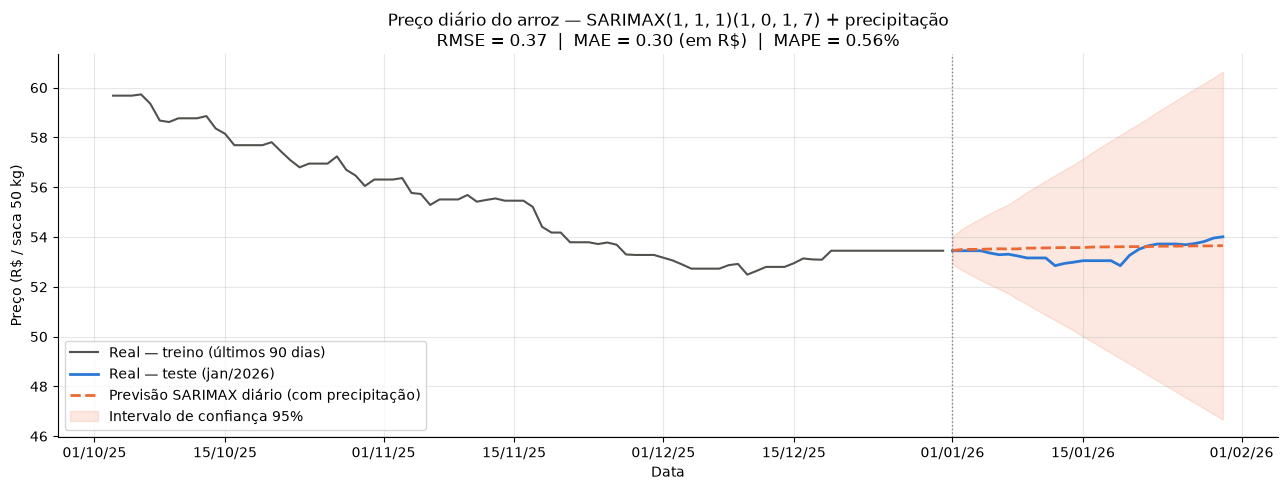

In [10]:
contexto = y_treino.iloc[-90:]   # últimos 90 dias do treino

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(contexto, color="#52514e", lw=1.5, label="Real — treino (últimos 90 dias)")
ax.plot(y_teste,  color="#2a78d6", lw=2,   label="Real — teste (jan/2026)")
ax.plot(y_prev,   color="#eb6834", lw=2, ls="--", label="Previsão SARIMAX diário (com precipitação)")
ax.fill_between(intervalo.index, intervalo.iloc[:, 0], intervalo.iloc[:, 1],
                color="#eb6834", alpha=0.15, label="Intervalo de confiança 95%")
ax.axvline(y_teste.index[0], color="gray", ls=":", lw=1)   # linha do corte treino/teste

ax.set_title(f"Preço diário do arroz — SARIMAX{ORDEM}{ORDEM_SAZONAL} + precipitação\n"
             f"RMSE = {rmse:.2f}  |  MAE = {mae:.2f} (em R$)  |  MAPE = {mape:.2f}%")
ax.set_xlabel("Data")
ax.set_ylabel("Preço (R$ / saca 50 kg)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y"))
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower left")

plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/sarimax_previsao.png", dpi=150)
plt.show()

### 5.2 Exportação das métricas

Salvamos as métricas em CSV, no mesmo formato dos demais modelos, para montar a tabela comparativa com XGBoost e LSTM.

In [11]:
pd.DataFrame({"modelo": ["SARIMAX"], "RMSE": [rmse], "MAE": [mae], "MAPE": [mape]}) \
  .round(4).to_csv(f"{PASTA_SAIDA}/metricas_sarimax.csv", index=False)

print(f"Gráfico salvo em {PASTA_SAIDA}/sarimax_previsao.png")
print(f"Métricas salvas em {PASTA_SAIDA}/metricas_sarimax.csv")
pd.read_csv(f"{PASTA_SAIDA}/metricas_sarimax.csv")

Gráfico salvo em outputs/sarimax_previsao.png
Métricas salvas em outputs/metricas_sarimax.csv


,modelo,RMSE,MAE,MAPE
0,SARIMAX,0.3718,0.2957,0.556


## Conclusão

- **Ajuste:** o otimizador convergiu e todos os termos ARMA (não sazonais e semanais) foram altamente significativos, confirmando
  a dependência de curto prazo e o ciclo semanal do preço diário. O teste de Ljung-Box (Prob(Q) alto) indica que não sobrou
  autocorrelação relevante nos resíduos.
- **Precipitação:** o coeficiente da chuva **não foi estatisticamente significativo** (p-valor bem acima de 0,05).
  A chuva **do mesmo dia** não explica a variação diária do preço: o efeito do clima sobre a oferta de arroz tende a aparecer
  com **defasagem** (semanas ou meses, via safra e colheita), e não de forma imediata.
- **Previsão:** no horizonte de 30 dias de janeiro de 2026, o erro médio ficou em torno de **R\$ 0,30 por saca (MAPE ≈ 0,6%)**.
  O valor baixo reflete, em grande parte, a **inércia do preço diário**: de um dia para o outro o preço muda pouco, então a
  previsão próxima do último valor observado já é competitiva no curto prazo.
- **Limitações:** o resumo do modelo mostra **heterocedasticidade** (H elevado) e **caudas pesadas** (curtose alta), herança de choques
  como a pandemia e as enchentes de 2024. O intervalo de confiança deve, portanto, ser lido com cautela.
- **Próximos passos:** testar a precipitação **defasada ou acumulada** (ex.: chuva dos últimos 30 dias) e comparar o SARIMAX com os
  modelos não lineares (XGBoost e LSTM), que podem captar relações mais complexas entre clima e preço.